# 05.1 — RNNs, LSTMs and GRUs

How networks process sequences step by step, why plain RNNs forget, how LSTM and GRU gates fix it,
and why attention and transformers replaced them.

## What's in this notebook

- 1\. Sequence data
- 2\. The recurrent neural network
- 3\. Vanishing and exploding gradients through time
- 4\. LSTM
- 5\. GRU
- 6\. A memory test: remember the first token
- 7\. RNNs in PyTorch: shapes, stacking, bidirectional, packing
- 8\. From seq2seq to attention
- 9\. Trade-offs
- 10\. Interview questions
- 11\. In my own words

In [1]:
import time

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn

VOCAB = 8                                            # tokens 0..7 in the memory task (section 6)


def make_batch(n: int, length: int, generator: torch.Generator) -> tuple[torch.Tensor, torch.Tensor]:
    """Random token sequences, one-hot encoded; the label is the FIRST token."""
    tokens = torch.randint(0, VOCAB, (n, length), generator=generator)
    return F.one_hot(tokens, VOCAB).float(), tokens[:, 0]

# 1. SEQUENCE DATA

Text, speech, sensor readings and prices are sequences: the order matters, the length varies, and an early element can change the meaning of a late one.
An MLP needs a fixed-size input and has no notion of order; a CNN only sees a fixed window.

| Shape of the task | Example |
|---|---|
| many to one | sentiment of a review, classifying a sensor trace |
| many to many (same length) | tagging each word (named entities), labelling each frame of audio |
| sequence to sequence (different lengths) | translation, summarization, speech to text |
| one to many | generating text or music from a prompt |

# 2. THE RECURRENT NEURAL NETWORK

An **RNN** reads the sequence one step at a time and keeps a **hidden state** `h`, a summary of everything seen so far.
At each step it combines the new input with the previous state, **using the same weights at every step**:

```text
h_t = tanh(W_x · x_t + W_h · h_(t−1) + b)

x_1      x_2      x_3              unrolled over time: the same cell, the same weights,
 │        │        │               applied once per step
h_0 ─► [cell] ─► [cell] ─► [cell] ─► h_3   →  prediction (many to one)
```

Training **unrolls** the loop and runs ordinary backprop through all the steps: **backpropagation through time (BPTT)**.
For long sequences, **truncated BPTT** backpropagates through only the last k steps to save memory and time.

The loop below is exactly what `nn.RNN` computes:

In [2]:
torch.manual_seed(0)
rnn = nn.RNN(input_size=3, hidden_size=4, batch_first=True)
x = torch.randn(2, 5, 3)                                   # batch of 2 sequences, 5 time steps, 3 features each
out, h_last = rnn(x)

h = torch.zeros(2, 4)
steps = []
for t in range(5):
    h = torch.tanh(x[:, t] @ rnn.weight_ih_l0.T + rnn.bias_ih_l0 + h @ rnn.weight_hh_l0.T + rnn.bias_hh_l0)
    steps.append(h)
by_hand = torch.stack(steps, dim=1)

print("nn.RNN output (every step):", tuple(out.shape), "| final hidden state:", tuple(h_last.shape))
print("the loop by hand matches nn.RNN:", torch.allclose(by_hand, out, atol=1e-6))

nn.RNN output (every step): (2, 5, 4) | final hidden state: (1, 2, 4)
the loop by hand matches nn.RNN: True


# 3. VANISHING AND EXPLODING GRADIENTS THROUGH TIME

To learn that step 1 matters for the prediction at step 100, the gradient has to travel back through 100 copies of the cell.
Each step multiplies it by `W_h` and the tanh derivative (at most 1). If those factors are below 1 the gradient **vanishes** exponentially;
above 1 it **explodes**. It's the deep-network problem from 03.2, with the sequence length as the depth.
- Exploding gradients are fixed with **gradient clipping** (03.3).
- Vanishing gradients need a different architecture: **gates** (LSTM, GRU), or attention.

The gradient of the prediction with respect to each input step, for untrained models on a 100-step sequence:

RNN                       gradient at step 1: 8.2e-21   step 50: 2.7e-11   step 100: 2.0e-01
LSTM, default init        gradient at step 1: 3.3e-21   step 50: 7.3e-12   step 100: 6.0e-02
LSTM, forget-gate bias 3  gradient at step 1: 1.2e-01   step 50: 2.5e-02   step 100: 7.4e-02
GRU, update-gate bias 3   gradient at step 1: 2.9e-04   step 50: 1.5e-03   step 100: 1.4e-02


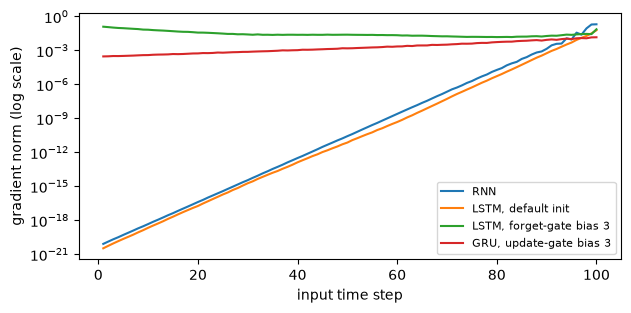

In [3]:
class SequenceClassifier(nn.Module):
    def __init__(self, kind: str, hidden: int = 64, gate_bias: float = 0.0):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind](VOCAB, hidden, batch_first=True)
        self.head = nn.Linear(hidden, VOCAB)
        if gate_bias:   # open the "keep the memory" gate at the start: the LSTM forget gate / the GRU update gate
            with torch.no_grad():
                self.rnn.bias_ih_l0[hidden:2 * hidden].fill_(gate_bias)
                self.rnn.bias_hh_l0[hidden:2 * hidden].zero_()

    def forward(self, x):
        out, _ = self.rnn(x)                       # (batch, time, hidden)
        return self.head(out[:, -1])               # predict from the last step


def input_gradients(model: nn.Module, length: int = 100) -> torch.Tensor:
    x, _ = make_batch(1, length, torch.Generator().manual_seed(0))
    x.requires_grad_(True)
    model(x)[0].sum().backward()
    return x.grad[0].norm(dim=1)                   # one value per time step


setups = {"RNN": ("RNN", 0.0), "LSTM, default init": ("LSTM", 0.0), "LSTM, forget-gate bias 3": ("LSTM", 3.0), "GRU, update-gate bias 3": ("GRU", 3.0)}
plt.figure(figsize=(7, 3.2))
for name, (kind, bias) in setups.items():
    torch.manual_seed(0)
    grads = input_gradients(SequenceClassifier(kind, gate_bias=bias))
    print(f"{name:<25} gradient at step 1: {grads[0]:.1e}   step 50: {grads[49]:.1e}   step 100: {grads[99]:.1e}")
    plt.semilogy(range(1, 101), grads, label=name)
plt.xlabel("input time step")
plt.ylabel("gradient norm (log scale)")
plt.legend(fontsize=8)
plt.show()

The plain RNN and the default LSTM look alike: the gradient from step 1 is about 1e-21, twenty orders of magnitude below step 100, so the first token can't influence learning. With the forget-gate bias set to 3, the LSTM's gradient at step 1 (0.12) is as large as at step 100 (0.07): the memory line is open. The GRU with an open update gate is in between (3e-4 at step 1).

# 4. LSTM

The **LSTM** (Long Short-Term Memory, 1997) adds a **cell state** `c`, a memory line that runs through time and is changed only by
element-wise multiplication and addition. Three **gates**, each a sigmoid between 0 and 1, decide what happens to it:

```text
f = σ(W_f · [h_(t−1), x_t] + b_f)        forget gate: how much of the old memory to keep
i = σ(W_i · [h_(t−1), x_t] + b_i)        input gate: how much new information to write
g = tanh(W_g · [h_(t−1), x_t] + b_g)     the candidate new information
o = σ(W_o · [h_(t−1), x_t] + b_o)        output gate: how much of the memory to show

c_t = f ⊙ c_(t−1) + i ⊙ g                the memory update is additive
h_t = o ⊙ tanh(c_t)
```

When the forget gate is close to 1, `c` passes through almost unchanged, and so does its gradient: a path through time without repeated squashing,
like a residual connection (03.2). The LSTM has 4 sets of weights, so about 4 times the parameters of a plain RNN of the same size.

**The forget-gate bias:** PyTorch starts the forget gate around 0.5, which halves the memory at every step (section 3).
Setting its bias to 1 or more at the start (Keras does this by default) keeps the memory open until the model learns what to forget.

# 5. GRU

The **GRU** (Gated Recurrent Unit, 2014) is a simpler gated cell: no separate cell state, and two gates.

```text
r = σ(W_r · [h_(t−1), x_t])                       reset gate: how much of the past to use for the new candidate
z = σ(W_z · [h_(t−1), x_t])                       update gate: how much of the old state to keep
n = tanh(W_n · [r ⊙ h_(t−1), x_t])                candidate state
h_t = (1 − z) ⊙ n + z ⊙ h_(t−1)                   (PyTorch's convention)
```

It has 3 sets of weights instead of 4, trains a bit faster, and usually performs about as well as an LSTM.

In [4]:
for kind in ["RNN", "GRU", "LSTM"]:
    layer = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[kind](input_size=64, hidden_size=128)
    print(f"{kind:<5} input 64, hidden 128: {sum(p.numel() for p in layer.parameters()):,} parameters")

RNN   input 64, hidden 128: 24,832 parameters
GRU   input 64, hidden 128: 74,496 parameters
LSTM  input 64, hidden 128: 99,328 parameters


# 6. A MEMORY TEST: REMEMBER THE FIRST TOKEN

Each sequence is random tokens; the label is the **first** token, so the model must carry it through every later step.
Chance is 1/8 = 0.125. Four models, each trained for 1,500 steps (batch 64, Adam, gradient clipping at 1.0), on sequences of length 20 and 50.

In [5]:
def run_memory_test(kind: str, length: int, gate_bias: float = 0.0, steps: int = 1500) -> tuple[float, int | None]:
    torch.manual_seed(0)
    model = SequenceClassifier(kind, gate_bias=gate_bias)
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
    generator = torch.Generator().manual_seed(0)
    learned_at = None
    for step in range(steps):
        x, y = make_batch(64, length, generator)
        optimizer.zero_grad()
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if learned_at is None and loss.item() < 0.1:
            learned_at = step
    x_test, y_test = make_batch(2000, length, torch.Generator().manual_seed(1))
    with torch.no_grad():
        return (model(x_test).argmax(1) == y_test).float().mean().item(), learned_at


for length in [20, 50]:
    for name, (kind, bias) in setups.items():
        start = time.perf_counter()
        acc, learned_at = run_memory_test(kind, length, bias)
        when = f"loss < 0.1 at step {learned_at}" if learned_at is not None else "never learned"
        print(f"length {length}, {name:<25} test accuracy {acc:.3f}   ({when}, {time.perf_counter() - start:.0f} s)")

length 20, RNN                       test accuracy 1.000   (loss < 0.1 at step 400, 4 s)


length 20, LSTM, default init        test accuracy 0.123   (never learned, 7 s)


length 20, LSTM, forget-gate bias 3  test accuracy 1.000   (loss < 0.1 at step 120, 8 s)


length 20, GRU, update-gate bias 3   test accuracy 1.000   (loss < 0.1 at step 219, 6 s)


length 50, RNN                       test accuracy 0.123   (never learned, 7 s)


length 50, LSTM, default init        test accuracy 0.131   (never learned, 16 s)


length 50, LSTM, forget-gate bias 3  test accuracy 1.000   (loss < 0.1 at step 504, 16 s)


length 50, GRU, update-gate bias 3   test accuracy 1.000   (loss < 0.1 at step 372, 13 s)


- **Length 20:** the plain RNN learns the task (after 400 steps), and the LSTM and GRU with open gates learn it faster (120 and 219 steps). The LSTM with PyTorch's default initialization never learns it: with its memory halving at every step, it does worse than the plain RNN.
- **Length 50:** the plain RNN fails (0.123, chance level), and so does the default LSTM. The LSTM and GRU with open gates both reach 1.000.

Gates make long memory possible, but only if they start open. Even then, longer dependencies take more and more training for every RNN. That is the problem attention solved.

# 7. RNNS IN PYTORCH: SHAPES, STACKING, BIDIRECTIONAL, PACKING

| Option | Meaning |
|---|---|
| `batch_first=True` | inputs and outputs are (batch, time, features); the default is (time, batch, features) |
| `num_layers=2` | stack RNNs: the second reads the first one's outputs |
| `bidirectional=True` | a second RNN reads the sequence backwards; outputs are concatenated (2 × hidden). Needs the whole sequence, so not for generation or streaming |
| outputs | `output`: the last layer's hidden state at **every** step; `h_n` (and `c_n` for LSTM): the **final** state of every layer and direction |
| packed sequences | `pack_padded_sequence` tells the RNN each sequence's real length, so padding (02.2 section 7) is skipped and `h_n` comes from the real last step |

In [6]:
torch.manual_seed(0)
sequences = [torch.randn(5, 3), torch.randn(2, 3), torch.randn(4, 3)]      # three sequences of lengths 5, 2 and 4
lengths = torch.tensor([5, 2, 4])
padded = nn.utils.rnn.pad_sequence(sequences, batch_first=True)             # (3, 5, 3), zeros after each real end

lstm = nn.LSTM(input_size=3, hidden_size=8, num_layers=2, bidirectional=True, batch_first=True)
packed = nn.utils.rnn.pack_padded_sequence(padded, lengths, batch_first=True, enforce_sorted=False)
packed_out, (h_n, c_n) = lstm(packed)
out, _ = nn.utils.rnn.pad_packed_sequence(packed_out, batch_first=True)

print("padded input:", tuple(padded.shape), "| output:", tuple(out.shape), "(2 directions x 8)", "| h_n:", tuple(h_n.shape), "(2 layers x 2 directions, batch, hidden)")
print("final forward state of the length-2 sequence = its output at step 2, not at the padding:", torch.allclose(h_n[-2][1], out[1, 1, :8]))

padded input: (3, 5, 3) | output: (3, 5, 16) (2 directions x 8) | h_n: (4, 3, 8) (2 layers x 2 directions, batch, hidden)
final forward state of the length-2 sequence = its output at step 2, not at the padding: True


# 8. FROM SEQ2SEQ TO ATTENTION

- **Seq2seq (2014):** an encoder RNN reads the input sentence into one final hidden state; a decoder RNN generates the output from it. That was the first neural translation.
- **The bottleneck:** the whole input sentence has to fit in one fixed-size vector, so quality drops on long sentences.
- **Attention (2015):** at each output step, the decoder scores *every* encoder state, takes a weighted average, and focuses on the relevant words. No more single bottleneck.
- **Transformer (2017, "Attention Is All You Need"):** drop the recurrence entirely and use attention between all positions (folder 06).

| | RNN / LSTM | Transformer |
|---|---|---|
| training | step by step, can't parallelize over time | all positions at once, fully parallel on GPUs |
| path between distant tokens | through every step in between | one attention step |
| cost in sequence length n | O(n) | O(n²) attention |
| memory when generating | a fixed-size state | a KV cache that grows with the context (folder 07) |
| where it's used today | streaming, small on-device models, some time series | almost all of NLP, LLMs, and much of vision and speech |

Recurrence is coming back in a new form: **state-space models** (Mamba) and RNN-style models such as RWKV train in parallel like transformers
but generate with a fixed-size state, and some recent LLMs mix them with attention layers.

# 9. TRADE-OFFS

| Decision | Options | What you gain and what you pay | Usual choice |
|---|---|---|---|
| Recurrent cell | RNN / LSTM / GRU | RNN: fewest parameters, can't hold long-range memory. LSTM: strongest memory, 4x the parameters. GRU: nearly as good with 3x, a little faster | GRU or LSTM; plain RNN only for very short dependencies |
| Gate bias at the start | default / forget (update) gate bias of 1–3 | default in PyTorch: memory halves each step until learned. Open gate: learns long dependencies much sooner (section 6) | set it; Keras does by default |
| Direction | unidirectional / bidirectional | bidirectional: uses the future context too, so better for tagging and classification; impossible for generation and streaming | bidirectional when the full sequence is available |
| Variable lengths | pad only / pad + pack / masking | padding alone lets the RNN read zeros and take the final state at padding. Packing skips them. Masking does the same for attention models | packing for RNNs, attention masks for transformers |
| Long sequences | full BPTT / truncated BPTT | full: exact gradients, memory grows with length. Truncated: bounded memory, can't learn dependencies longer than the window | truncated for very long streams |
| Architecture today | LSTM / transformer / state-space model | LSTM: small, streaming-friendly, weaker on long context. Transformer: best quality, O(n²). SSMs: linear cost, newer | transformers by default; RNNs or SSMs for streaming or tight memory |

# 10. INTERVIEW QUESTIONS

### Q1. How does an RNN work, in 30 seconds?
It processes a sequence one step at a time, keeping a hidden state that summarizes everything seen so far. Each step combines the current input with the previous hidden state
using the same weights, so it handles any length. It's trained with backpropagation through time over the unrolled steps.

### Q2. Why do RNNs suffer from vanishing and exploding gradients?
The gradient flowing back through time is multiplied by the recurrent weight matrix and the activation's derivative at every step. Over many steps it shrinks or grows exponentially.
Exploding gradients are fixed by clipping; vanishing gradients by gated cells (LSTM, GRU) or by attention.

### Q3. How does an LSTM avoid vanishing gradients?
Its cell state is updated additively, `c_t = f ⊙ c_(t−1) + i ⊙ g`, controlled by learned gates. When the forget gate is near 1, information and gradients pass through many steps almost unchanged,
like a residual connection through time.

### Q4. LSTM vs GRU?
The GRU merges the cell and hidden state and uses two gates (reset, update) instead of three, so it has about 25% fewer parameters and runs faster.
Performance is usually similar; LSTMs sometimes do better on very long dependencies.

### Q5. Why initialize the LSTM forget-gate bias to 1 or more?
With a bias of 0 the forget gate starts at about 0.5, so the memory halves at every step and long-range gradients vanish before the model learns anything.
A positive bias keeps the memory open at the start. In section 6, the LSTM failed at length 20 with the default init and learned length 50 with a bias of 3.

### Q6. What are BPTT and truncated BPTT?
BPTT unrolls the RNN over the sequence and backpropagates through every step. Truncated BPTT backpropagates through only the last k steps (carrying the hidden state forward without gradient),
which bounds memory and time but can't learn dependencies longer than k.

### Q7. How do you handle variable-length sequences in an RNN?
Pad them to the batch's longest length, then pack them with `pack_padded_sequence` so the RNN skips the padding and returns the final state at each sequence's true end.
Mask the padding in the loss and in any pooling.

### Q8. What is a bidirectional RNN, and when can't you use one?
Two RNNs, one reading forwards and one backwards, with their outputs concatenated, so each position sees both past and future context. It can't be used when the future isn't available:
text generation, real-time streaming or online prediction.

### Q9. What is the bottleneck in seq2seq models, and how does attention fix it?
The encoder compresses the entire input into one fixed-size vector, which loses information for long inputs. Attention lets the decoder look at all encoder states at every step
and weight them by relevance, so nothing has to fit in one vector.

### Q10. Why did transformers replace RNNs?
RNNs process tokens sequentially, so training can't be parallelized over time, and information between distant tokens passes through many steps.
Transformers use attention to connect every pair of positions directly and process all positions in parallel, which trains far faster on GPUs and scales to huge datasets.

### Q11. Are RNNs still used?
Yes, where their fixed-size state helps: streaming speech and sensor data, small on-device models, and some forecasting. State-space models such as Mamba,
and RWKV, bring recurrent-style generation back, combined with transformer-style parallel training.

### Q12. What's the difference between `output` and `h_n` from `nn.LSTM`?
`output` holds the last layer's hidden state at every time step: shape (batch, time, directions × hidden). `h_n` (and `c_n`) holds only the final step's state for every layer and direction:
shape (layers × directions, batch, hidden). Use `output` for tagging and attention, `h_n` (or the last real output) for classification.

# 11. IN MY OWN WORDS

Write this from memory, without looking above:

- How an RNN processes a sequence:
- Why gradients vanish through time:
- The LSTM gates and the cell state:
- Why the forget-gate bias matters:
- Why attention and transformers replaced RNNs: